# Extreme wave events in 2005: what changes, and how do RF and U-Net cope?

**Storm day** = a day whose daily-average Hm0 over all ocean cells is above the **90th percentile**
of the 365 daily averages of 2005. Consecutive storm days are grouped into one event.

1. Find the storm days and events.
2. Compare the atmospheric inputs (wind, pressure, direction, previous-day wind) on storm days vs other days.
3. Model errors on storm days vs other days. **Only the Oct–Dec test period is used for this**, because both
   models were trained on Jan–Aug. Same models as the comparison: RF with the notebook settings
   (600k Jan–Aug rows) and the U-Net from `iEMs_UNet.ipynb` (`unet_best.pt`).

The first cells are the setup cells of `iEMs_UNet.ipynb`, unchanged.

In [1]:
from __future__ import annotations

import time
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
# -----------------------------
# USER SETTINGS
# -----------------------------
# Data: read X_2005.txt / Y_2005.txt from DATA_DIR if present, otherwise straight from the zip.
DATA_DIR = Path("../../Copy of Dataset and code - Wave Power")
ZIP_PATH = Path("../../Copy of Dataset and code - Wave Power.zip")
X_NAME, Y_NAME = "X_2005.txt", "Y_2005.txt"

OUTDIR = Path("unet_2005_outputs")
OUTDIR.mkdir(exist_ok=True, parents=True)
GRID_CACHE = OUTDIR / "grids_2005.npz"   # parsed (time, lat, lon) arrays; delete to re-parse

RANDOM_SEED = 42

# Chronological split, as [start, end) hour indices (2005 is hourly: 8760 steps)
TRAIN_HOURS = (0, 243 * 24)          # 1 Jan – 31 Aug
VAL_HOURS   = (243 * 24, 273 * 24)   # September (early stopping / LR schedule)
TEST_HOURS  = (273 * 24, 365 * 24)   # 1 Oct – 31 Dec

# Wind/pressure history fed to the network: fields at t - lag for each lag (hours).
# Waves respond to wind over the previous hours, and swell arrives from upwind.
LAGS = [0, 1, 3, 6, 12, 24]

# U-Net
BASE_CHANNELS = 32
DEPTH = 3            # number of 2x downsamplings; the grid is zero-padded to a multiple of 2**DEPTH
DROPOUT = 0.1        # also used for the MC-dropout uncertainty band

# Training
BATCH_SIZE = 32
EPOCHS = 40
LR = 1e-3
WEIGHT_DECAY = 1e-4
PATIENCE = 8         # early stopping on validation RMSE

# Plot settings
MC_SAMPLES = 20
PLOT_SUBSAMPLE = 60_000
CI_BINS = 80
ADD_PM10_ENVELOPE = True

PAIRS_OUT = OUTDIR / "actual_vs_predicted_test_sample.txt"
PAIRS_SEP = "\t"

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
print("Device:", DEVICE)

Device: cuda


In [3]:
# -----------------------------
# LOAD ROWS -> (time, lat, lon) GRIDS
# -----------------------------
def open_source(name: str):
    p = DATA_DIR / name
    if p.exists():
        return open(p, "rb")
    return zipfile.ZipFile(ZIP_PATH).open(name)


def load_grids() -> dict:
    if GRID_CACHE.exists():
        with np.load(GRID_CACHE) as d:
            return {k: d[k] for k in d.files}

    print("Parsing text files (one-off, cached afterwards)...")
    with open_source(X_NAME) as f:
        X = pd.read_csv(f, header=None, usecols=range(5), dtype=np.float32).to_numpy()
    with open_source(Y_NAME) as f:
        y = pd.read_csv(f, header=None, usecols=[0], dtype=np.float32).to_numpy()[:, 0]
    if len(X) != len(y):
        raise ValueError(f"X has {len(X)} rows but Y has {len(y)}")

    lat_vals = np.unique(X[:, 0])
    lon_vals = np.unique(X[:, 1])
    nlat, nlon = len(lat_vals), len(lon_vals)
    ncell = nlat * nlon
    if len(X) % ncell:
        raise ValueError(f"{len(X)} rows is not a whole number of {nlat}x{nlon} grids")
    nt = len(X) // ncell

    # rows come as consecutive blocks of one full grid per hour
    t = np.arange(len(X)) // ncell
    ilat = np.searchsorted(lat_vals, X[:, 0])
    ilon = np.searchsorted(lon_vals, X[:, 1])
    counts = np.bincount((t * nlat + ilat) * nlon + ilon, minlength=nt * ncell)
    if not (counts == 1).all():
        raise ValueError("Rows are not one-per-cell-per-hour blocks; cannot reshape to grids.")

    fields = np.full((nt, 3, nlat, nlon), np.nan, dtype=np.float32)   # u10, v10, MSLP
    fields[t, :, ilat, ilon] = X[:, 2:5]
    hm0 = np.full((nt, nlat, nlon), np.nan, dtype=np.float32)
    hm0[t, ilat, ilon] = y

    grids = dict(fields=fields, hm0=hm0, lat=lat_vals, lon=lon_vals)
    np.savez(GRID_CACHE, **grids)
    return grids


grids = load_grids()
NT, NLAT, NLON = grids["hm0"].shape
OCEAN = np.isfinite(grids["hm0"]).all(axis=0)   # cells with Hm0 at every hour
LAT, LON = grids["lat"], grids["lon"]
print(f"{NT} hours x {NLAT} lat x {NLON} lon; ocean cells: {OCEAN.sum()} / {OCEAN.size}")
print(f"Lat {LAT.min()}..{LAT.max()}, Lon {LON.min()}..{LON.max()}")
assert TEST_HOURS[1] <= NT, "TEST_HOURS goes past the end of the data"

8760 hours x 29 lat x 45 lon; ocean cells: 967 / 1305
Lat 50.0..57.0, Lon -15.0..-4.0


In [4]:
# -----------------------------
# INPUT CHANNELS (normalised, padded)
# -----------------------------
VARS = ["u10", "v10", "wind_speed", "MSLP"]
STATIC_NAMES = ["Lat", "Lon", "ocean_mask"]

u, v, p = (grids["fields"][:, i] for i in range(3))
dyn = np.stack([u, v, np.hypot(u, v), p], axis=1)          # (T, 4, H, W)

# normalise with training-period statistics only
train_slice = slice(*TRAIN_HOURS)
mu = np.nanmean(dyn[train_slice], axis=(0, 2, 3)).reshape(1, -1, 1, 1)
sd = np.nanstd(dyn[train_slice], axis=(0, 2, 3)).reshape(1, -1, 1, 1)
dyn = np.nan_to_num((dyn - mu) / sd).astype(np.float32)

lat2d, lon2d = np.meshgrid(LAT, LON, indexing="ij")
scale = lambda a: (2 * (a - a.min()) / (a.max() - a.min()) - 1).astype(np.float32)
static = np.stack([scale(lat2d), scale(lon2d), OCEAN.astype(np.float32)])   # (3, H, W)

# pad H, W up to a multiple of 2**DEPTH (padding is masked out of the loss)
mult = 2 ** DEPTH
PH, PW = -NLAT % mult, -NLON % mult
DYN = np.pad(dyn, ((0, 0), (0, 0), (0, PH), (0, PW)))
STATIC = np.pad(static, ((0, 0), (0, PH), (0, PW)))
TARGET = np.pad(grids["hm0"], ((0, 0), (0, PH), (0, PW)), constant_values=np.nan)
TARGET[:, ~np.pad(OCEAN, ((0, PH), (0, PW)))] = np.nan

LAG_ARR = np.asarray(LAGS)
CHANNEL_NAMES = [f"{var}_lag{L}h" for L in LAGS for var in VARS] + STATIC_NAMES
N_IN = len(CHANNEL_NAMES)

first_valid = max(LAGS)   # need full history
train_times = np.arange(max(TRAIN_HOURS[0], first_valid), TRAIN_HOURS[1])
val_times = np.arange(max(VAL_HOURS[0], first_valid), VAL_HOURS[1])
test_times = np.arange(max(TEST_HOURS[0], first_valid), TEST_HOURS[1])
print(f"Input channels: {N_IN}, padded grid: {DYN.shape[-2]}x{DYN.shape[-1]}")
print(f"Train/val/test maps: {len(train_times)} / {len(val_times)} / {len(test_times)}")


def make_batch(times, shuffled_vars: dict | None = None):
    # Stack lagged fields + static channels for the given hours.
    # shuffled_vars maps a variable index (into VARS) to replacement hours, used for
    # permutation importance (that variable is taken from other hours, at all lags).
    times = np.asarray(times)
    x = DYN[times[:, None] - LAG_ARR[None, :]].copy()        # (B, nlag, 4, H, W)
    for vi, other in (shuffled_vars or {}).items():
        x[:, :, vi] = DYN[np.asarray(other)[:, None] - LAG_ARR[None, :], vi]
    x = x.reshape(len(times), -1, *x.shape[-2:])
    s = np.broadcast_to(STATIC, (len(times),) + STATIC.shape)
    x = np.concatenate([x, s], axis=1)
    return torch.from_numpy(x).to(DEVICE), torch.from_numpy(TARGET[times]).to(DEVICE)

Input channels: 27, padded grid: 32x48
Train/val/test maps: 5808 / 720 / 2208


In [5]:
# -----------------------------
# U-NET
# -----------------------------
def conv_block(cin: int, cout: int, dropout: float) -> nn.Sequential:
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1, bias=False),
        nn.BatchNorm2d(cout),
        nn.ReLU(inplace=True),
        nn.Dropout2d(dropout),
        nn.Conv2d(cout, cout, 3, padding=1, bias=False),
        nn.BatchNorm2d(cout),
        nn.ReLU(inplace=True),
    )


class UNet(nn.Module):
    def __init__(self, in_ch: int, base: int = 32, depth: int = 3, dropout: float = 0.1):
        super().__init__()
        chs = [base * 2 ** i for i in range(depth + 1)]
        self.down = nn.ModuleList()
        prev = in_ch
        for c in chs[:-1]:
            self.down.append(conv_block(prev, c, dropout))
            prev = c
        self.bottleneck = conv_block(prev, chs[-1], dropout)
        self.up = nn.ModuleList(
            nn.ConvTranspose2d(chs[i + 1], chs[i], 2, stride=2) for i in reversed(range(depth))
        )
        self.dec = nn.ModuleList(conv_block(2 * chs[i], chs[i], dropout) for i in reversed(range(depth)))
        self.head = nn.Conv2d(chs[0], 1, 1)

    def forward(self, x):
        skips = []
        for block in self.down:
            x = block(x)
            skips.append(x)
            x = F.max_pool2d(x, 2)
        x = self.bottleneck(x)
        for up, dec, skip in zip(self.up, self.dec, reversed(skips)):
            x = dec(torch.cat([up(x), skip], dim=1))
        return self.head(x).squeeze(1)   # (B, H, W) Hm0 in metres


def masked_mse(pred, target):
    m = torch.isfinite(target)
    return F.mse_loss(pred[m], target[m])


model = UNet(N_IN, BASE_CHANNELS, DEPTH, DROPOUT).to(DEVICE)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

Parameters: 1,933,921


In [6]:
# -----------------------------
# PREDICTION HELPERS
# -----------------------------
@torch.no_grad()
def predict(model, times, mc_dropout: bool = False, shuffled_vars: dict | None = None) -> np.ndarray:
    # Hm0 maps (len(times), NLAT, NLON); land cells are NaN.
    model.eval()
    if mc_dropout:   # dropout on, batch-norm still in eval mode
        for mod in model.modules():
            if isinstance(mod, nn.Dropout2d):
                mod.train()
    out = []
    for i in range(0, len(times), 2 * BATCH_SIZE):
        sl = slice(i, i + 2 * BATCH_SIZE)
        sv = {k: np.asarray(o)[sl] for k, o in (shuffled_vars or {}).items()}
        xb, _ = make_batch(times[sl], sv)
        out.append(model(xb).float().cpu().numpy())
    pred = np.concatenate(out)[:, :NLAT, :NLON].clip(min=0)
    pred[:, ~OCEAN] = np.nan
    return pred


def obs_maps(times) -> np.ndarray:
    o = grids["hm0"][times].copy()
    o[:, ~OCEAN] = np.nan
    return o


def rmse_of(obs, pred) -> float:
    m = np.isfinite(obs) & np.isfinite(pred)
    return float(np.sqrt(np.mean((obs[m] - pred[m]) ** 2)))

In [7]:
# -----------------------------
# DAILY DOMAIN-AVERAGE SERIES + STORM DAYS
# -----------------------------
from sklearn.ensemble import RandomForestRegressor

EXT_DIR = Path("../../results/5_extremes")
EXT_DIR.mkdir(exist_ok=True, parents=True)
PCTL = 90

COLOR = {"Observed": "#1f1f1f", "Random Forest": "#2a78d6", "U-Net": "#eb6834"}
STORM_C, NORMAL_C = "#e34948", "#8a8a8a"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True})

ND = NT // 24
dates = pd.date_range("2005-01-01", periods=ND, freq="D")
u, v, p = (grids["fields"][:, i] for i in range(3))
ws = np.hypot(u, v)

def ocean_mean(a):   # (T, H, W) -> (T,)
    return a[:, OCEAN].mean(axis=1)

def daily(x):        # hourly (T,) -> daily (ND,)
    return x[:ND * 24].reshape(ND, 24).mean(axis=1)

hm0_h = ocean_mean(grids["hm0"])
day = pd.DataFrame({
    "Hm0_mean": daily(hm0_h),
    "Hm0_max": grids["hm0"][:, OCEAN].max(axis=1)[:ND * 24].reshape(ND, 24).max(axis=1),
    "wind_speed": daily(ocean_mean(ws)),
    "wind_speed_max": ws[:, OCEAN].max(axis=1)[:ND * 24].reshape(ND, 24).max(axis=1),
    "u10": daily(ocean_mean(u)),
    "v10": daily(ocean_mean(v)),
    "MSLP": daily(ocean_mean(p)),
    "MSLP_min": p.reshape(NT, -1).min(axis=1)[:ND * 24].reshape(ND, 24).min(axis=1),
}, index=dates)
day["wind_speed_prev_day"] = day["wind_speed"].shift(1)
# direction the mean wind blows FROM (meteorological convention, degrees)
day["wind_dir_from"] = (270 - np.degrees(np.arctan2(day["v10"], day["u10"]))) % 360

thr = np.percentile(day["Hm0_mean"], PCTL)
day["storm"] = day["Hm0_mean"] > thr
day["period"] = np.where(day.index.month <= 8, "train (Jan–Aug)",
                         np.where(day.index.month == 9, "validation (Sep)", "test (Oct–Dec)"))
day.round(3).to_csv(EXT_DIR / "daily_series.csv")

print(f"P{PCTL} of daily-mean Hm0 = {thr:.2f} m -> {day.storm.sum()} storm days")
print(day.groupby("period")["storm"].agg(["sum", "count"]).rename(columns={"sum": "storm days", "count": "days"}))

P90 of daily-mean Hm0 = 4.31 m -> 37 storm days
                  storm days  days
period                            
test (Oct–Dec)            13    92
train (Jan–Aug)           22   243
validation (Sep)           2    30


In [8]:
# -----------------------------
# STORM EVENTS (consecutive storm days)
# -----------------------------
ev_id = (day["storm"] != day["storm"].shift()).cumsum()
events = []
for _, g in day[day["storm"]].groupby(ev_id[day["storm"]]):
    events.append({
        "start": g.index[0].date(), "end": g.index[-1].date(), "days": len(g),
        "peak_daily_mean_Hm0_m": g["Hm0_mean"].max(),
        "max_Hm0_any_cell_m": g["Hm0_max"].max(),
        "max_wind_speed_ms": g["wind_speed_max"].max(),
        "min_MSLP_hPa": g["MSLP_min"].min(),
        "mean_wind_dir_from_deg": g["wind_dir_from"].mean(),
        "period": g["period"].iloc[0],
    })
events = pd.DataFrame(events).sort_values("peak_daily_mean_Hm0_m", ascending=False)
events.round(2).to_csv(EXT_DIR / "storm_events.csv", index=False)
print(events.round(2).to_string(index=False))

     start        end  days  peak_daily_mean_Hm0_m  max_Hm0_any_cell_m  max_wind_speed_ms  min_MSLP_hPa  mean_wind_dir_from_deg           period
2005-01-17 2005-01-20     4                   9.13               13.65          23.980000    977.309998              276.070007  train (Jan–Aug)
2005-01-01 2005-01-12    12                   6.59               14.18          34.150002    946.330017              242.190002  train (Jan–Aug)
2005-12-31 2005-12-31     1                   6.35               10.02          22.049999    976.000000              295.589996   test (Oct–Dec)
2005-11-10 2005-11-12     3                   6.11               11.14          28.400000    970.270020              272.209991   test (Oct–Dec)
2005-11-25 2005-11-26     2                   6.04                8.92          21.920000    991.840027              180.020004   test (Oct–Dec)
2005-10-01 2005-10-01     1                   5.64                9.09          19.530001    996.280029              311.989990   

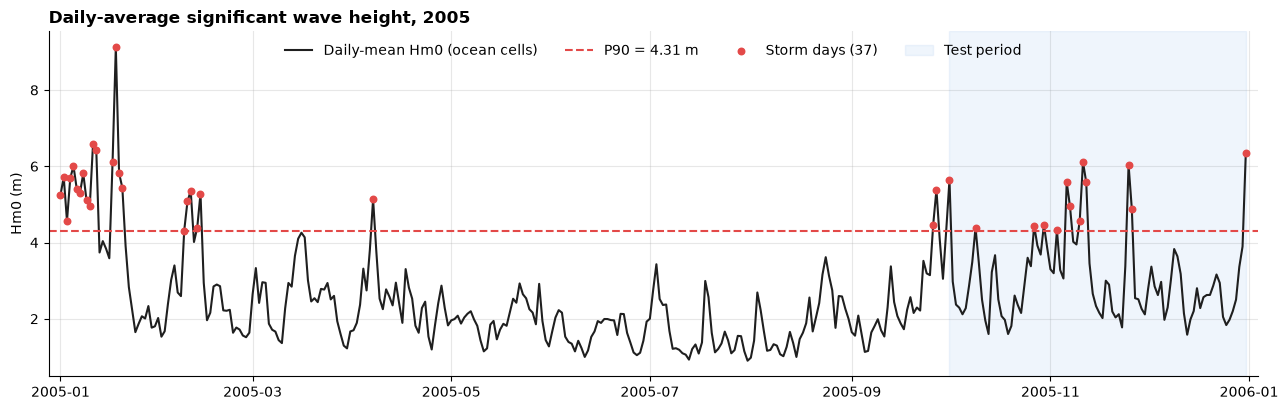

In [9]:
# -----------------------------
# TIME SERIES: daily-mean Hm0 with P90 and storm days
# -----------------------------
fig, ax = plt.subplots(figsize=(13, 4.2))
ax.plot(day.index, day["Hm0_mean"], color=COLOR["Observed"], lw=1.5, label="Daily-mean Hm0 (ocean cells)")
ax.axhline(thr, color=STORM_C, ls="--", lw=1.5, label=f"P{PCTL} = {thr:.2f} m")
ax.scatter(day.index[day.storm], day.loc[day.storm, "Hm0_mean"], color=STORM_C, s=22, zorder=3,
           label=f"Storm days ({day.storm.sum()})")
ax.axvspan(pd.Timestamp("2005-10-01"), day.index[-1], color="#2a78d6", alpha=0.07, label="Test period")
ax.set_ylabel("Hm0 (m)")
ax.set_title("Daily-average significant wave height, 2005", loc="left", fontweight="bold")
ax.legend(frameon=False, ncol=4, loc="upper center")
ax.margins(x=0.01)
fig.tight_layout()
fig.savefig(EXT_DIR / "storm_days_timeseries.png", dpi=300)
plt.show()

                           variable  other days (mean)  storm days (mean)  difference
              Mean wind speed (m/s)           7.870000          13.950000    6.080000
               Max wind speed (m/s)          14.580000          21.770000    7.190000
Mean wind speed, previous day (m/s)           7.950000          13.190000    5.240000
           Mean u10, eastward (m/s)           1.710000           9.260000    7.550000
          Mean v10, northward (m/s)           0.610000           1.610000    1.000000
                    Mean MSLP (hPa)        1016.369995        1008.419983   -7.960000
                     Min MSLP (hPa)        1004.669983         984.119995  -20.549999


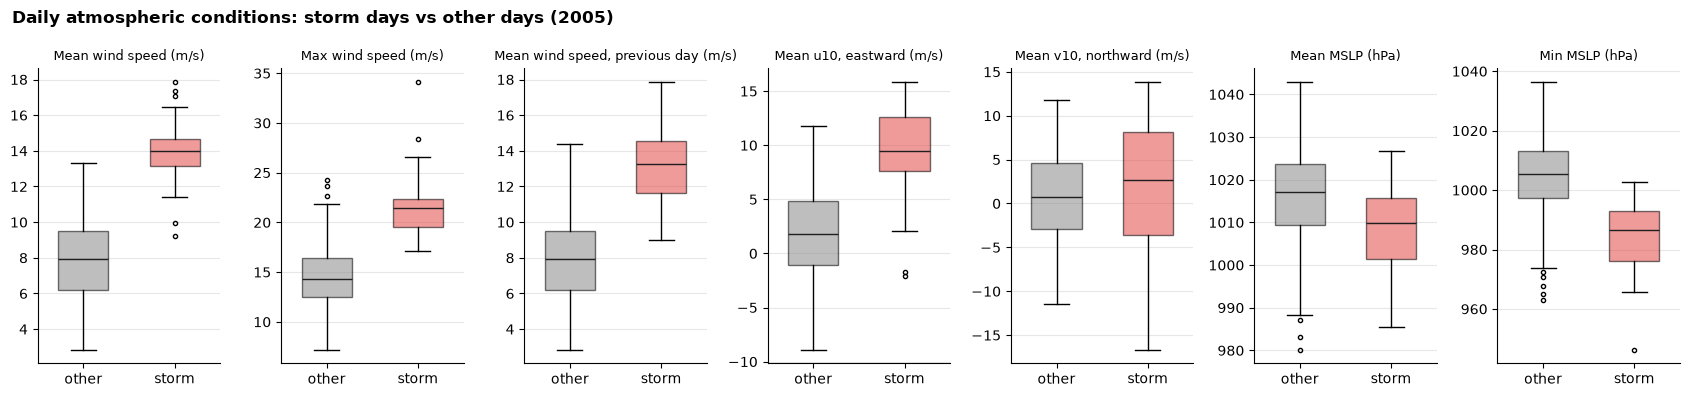

In [10]:
# -----------------------------
# WHAT CHANGES ON STORM DAYS? (whole year)
# -----------------------------
VARS_CMP = {
    "wind_speed": "Mean wind speed (m/s)",
    "wind_speed_max": "Max wind speed (m/s)",
    "wind_speed_prev_day": "Mean wind speed, previous day (m/s)",
    "u10": "Mean u10, eastward (m/s)",
    "v10": "Mean v10, northward (m/s)",
    "MSLP": "Mean MSLP (hPa)",
    "MSLP_min": "Min MSLP (hPa)",
}
s, n = day[day.storm], day[~day.storm]
cmp = pd.DataFrame({
    "variable": list(VARS_CMP.values()),
    "other days (mean)": [n[k].mean() for k in VARS_CMP],
    "storm days (mean)": [s[k].mean() for k in VARS_CMP],
})
cmp["difference"] = cmp["storm days (mean)"] - cmp["other days (mean)"]
cmp.round(2).to_csv(EXT_DIR / "storm_vs_other_variables.csv", index=False)
print(cmp.round(2).to_string(index=False))

fig, axes = plt.subplots(1, len(VARS_CMP), figsize=(17, 4))
for ax, (k, lab) in zip(axes, VARS_CMP.items()):
    bp = ax.boxplot([n[k].dropna(), s[k].dropna()], widths=0.55, patch_artist=True,
                    medianprops=dict(color="#1f1f1f"), flierprops=dict(ms=3))
    for patch, c in zip(bp["boxes"], [NORMAL_C, STORM_C]):
        patch.set_facecolor(c); patch.set_alpha(0.55)
    ax.set_xticks([1, 2], ["other", "storm"])
    ax.set_title(lab, fontsize=9)
    ax.grid(axis="x", visible=False)
fig.suptitle("Daily atmospheric conditions: storm days vs other days (2005)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(EXT_DIR / "storm_vs_other_boxplots.png", dpi=300)
plt.show()

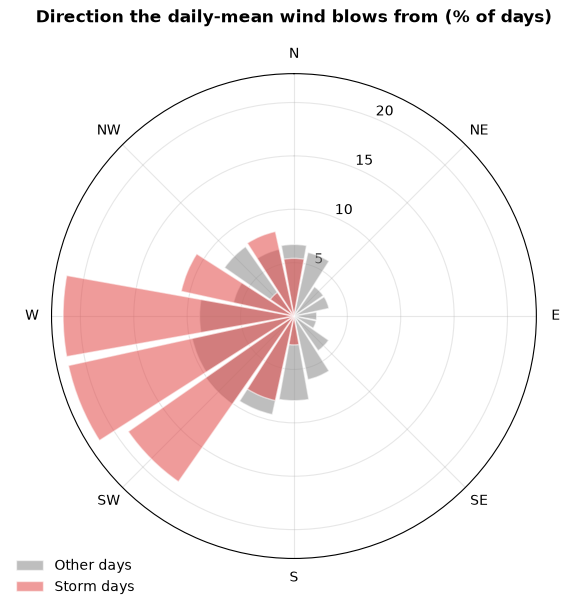

In [11]:
# -----------------------------
# WIND DIRECTION (wind rose of daily-mean wind)
# -----------------------------
nb = 16
edges = np.linspace(0, 360, nb + 1)
centers = np.radians(edges[:-1] + 360 / nb / 2)
fig, ax = plt.subplots(figsize=(6.2, 6.2), subplot_kw={"projection": "polar"})
for subset, c, lab in [(n, NORMAL_C, "Other days"), (s, STORM_C, "Storm days")]:
    shifted = (subset["wind_dir_from"] + 360 / nb / 2) % 360   # centre bins on N, NNE, ...
    h, _ = np.histogram(shifted, bins=edges)
    ax.bar(centers - np.radians(360 / nb / 2), 100 * h / h.sum(), width=np.radians(360 / nb) * 0.9,
           color=c, alpha=0.55, label=lab, edgecolor="white", linewidth=1)
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
ax.set_xticks(np.radians(np.arange(0, 360, 45)), ["N", "NE", "E", "SE", "S", "SW", "W", "NW"])
ax.set_title("Direction the daily-mean wind blows from (% of days)", fontweight="bold", pad=18)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(-0.1, -0.1))
fig.tight_layout()
fig.savefig(EXT_DIR / "wind_rose_storm_vs_other.png", dpi=300)
plt.show()

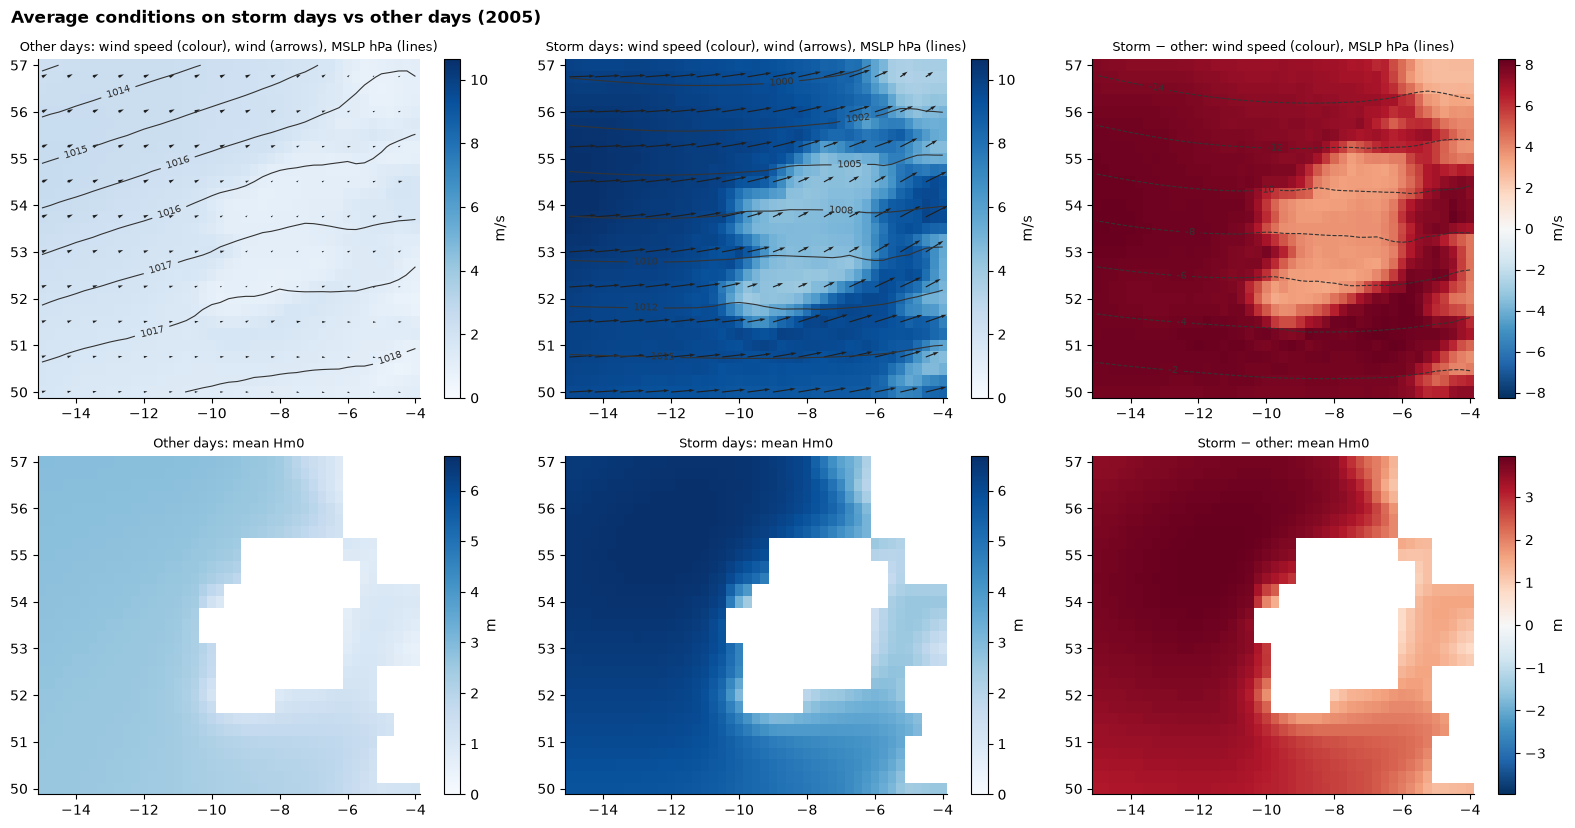

In [12]:
# -----------------------------
# COMPOSITE MAPS: wind and pressure, storm vs other days
# -----------------------------
d_lat = float(np.median(np.diff(LAT)))
d_lon = float(np.median(np.diff(LON)))
EXTENT = (LON.min() - d_lon / 2, LON.max() + d_lon / 2, LAT.min() - d_lat / 2, LAT.max() + d_lat / 2)

daily_f = grids["fields"][:ND * 24].reshape(ND, 24, 3, NLAT, NLON).mean(axis=1)   # (days, 3, H, W)
daily_h = grids["hm0"][:ND * 24].reshape(ND, 24, NLAT, NLON).mean(axis=1)
st = day["storm"].to_numpy()

def comp(mask):
    f = daily_f[mask].mean(axis=0)
    return f[0], f[1], np.hypot(f[0], f[1]), f[2], daily_h[mask].mean(axis=0)

panels = [("Other days", comp(~st)), ("Storm days", comp(st))]
fig, axes = plt.subplots(2, 3, figsize=(16, 8.4))
wmax = max(c[2].max() for _, c in panels)
hmax = max(np.nanmax(c[4]) for _, c in panels)
for col, (title, (uu, vv, ww, pp, hh)) in enumerate(panels):
    ax = axes[0, col]
    im = ax.imshow(ww, origin="lower", extent=EXTENT, aspect="auto", cmap="Blues", vmin=0, vmax=wmax)
    cs = ax.contour(LON, LAT, pp, colors="#333", linewidths=0.8)
    ax.clabel(cs, fontsize=7, fmt="%.0f")
    sk = 3
    ax.quiver(LON[::sk], LAT[::sk], uu[::sk, ::sk], vv[::sk, ::sk], color="#1f1f1f", scale=150, width=0.003)
    ax.set_title(f"{title}: wind speed (colour), wind (arrows), MSLP hPa (lines)", fontsize=9)
    fig.colorbar(im, ax=ax, label="m/s")
    ax = axes[1, col]
    im = ax.imshow(hh, origin="lower", extent=EXTENT, aspect="auto", cmap="Blues", vmin=0, vmax=hmax)
    ax.set_title(f"{title}: mean Hm0", fontsize=9)
    fig.colorbar(im, ax=ax, label="m")

(uS, vS, wS, pS, hS), (uN, vN, wN, pN, hN) = panels[1][1], panels[0][1]
ax = axes[0, 2]
lim = np.abs(wS - wN).max()
im = ax.imshow(wS - wN, origin="lower", extent=EXTENT, aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim)
cs = ax.contour(LON, LAT, pS - pN, colors="#333", linewidths=0.8)
ax.clabel(cs, fontsize=7, fmt="%.0f")
ax.set_title("Storm − other: wind speed (colour), MSLP hPa (lines)", fontsize=9)
fig.colorbar(im, ax=ax, label="m/s")
ax = axes[1, 2]
dh = hS - hN
lim = np.nanmax(np.abs(dh))
im = ax.imshow(dh, origin="lower", extent=EXTENT, aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim)
ax.set_title("Storm − other: mean Hm0", fontsize=9)
fig.colorbar(im, ax=ax, label="m")
for ax in axes.flat:
    ax.grid(False)
fig.suptitle("Average conditions on storm days vs other days (2005)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(EXT_DIR / "composite_maps_storm_vs_other.png", dpi=300)
plt.show()

In [13]:
# -----------------------------
# MODELS: predictions on the test period (Oct-Dec)
# -----------------------------
model = UNet(N_IN, BASE_CHANNELS, DEPTH, DROPOUT).to(DEVICE)
model.load_state_dict(torch.load(OUTDIR / "unet_best.pt", map_location=DEVICE))
pred_unet = predict(model, test_times)                       # (T_test, H, W), NaN on land

ocean_i, ocean_j = np.nonzero(OCEAN)

def rf_rows(times):
    f = grids["fields"][times][:, :, ocean_i, ocean_j]
    lat = np.broadcast_to(LAT[ocean_i], (len(times), len(ocean_i)))
    lon = np.broadcast_to(LON[ocean_j], (len(times), len(ocean_i)))
    X = np.stack([lat, lon, f[:, 0], f[:, 1], f[:, 2]], -1).reshape(-1, 5).astype(np.float32)
    return X, grids["hm0"][times][:, ocean_i, ocean_j].reshape(-1)

X_tr, y_tr = rf_rows(np.arange(*TRAIN_HOURS))
sel = np.random.default_rng(RANDOM_SEED).choice(len(y_tr), 600_000, replace=False)
t0 = time.time()
rf = RandomForestRegressor(n_estimators=300, random_state=RANDOM_SEED, n_jobs=-1,
                           min_samples_leaf=5, max_features="sqrt").fit(X_tr[sel], y_tr[sel])
del X_tr, y_tr
X_te, y_te = rf_rows(test_times)
pred_rf_cells = np.concatenate([rf.predict(X_te[i:i + 500_000]) for i in range(0, len(X_te), 500_000)])
print(f"RF trained and predicted in {time.time() - t0:.0f}s")

# everything as (T_test, ocean cells)
obs = y_te.reshape(len(test_times), -1)
preds = {"Random Forest": pred_rf_cells.reshape(len(test_times), -1),
         "U-Net": pred_unet[:, ocean_i, ocean_j]}
test_day = test_times // 24
storm_hour = day["storm"].to_numpy()[test_day]
print(f"Test period: {storm_hour.sum() // 24} storm days, {(~storm_hour).sum() // 24} other days")

RF trained and predicted in 60s
Test period: 13 storm days, 79 other days


        model                        days   MAE  RMSE  bias (obs−pred)     R2  mean obs Hm0       n
Random Forest                  storm days 1.078 1.370            0.822  0.426         5.179  301704
Random Forest                  other days 0.588 0.764            0.177  0.564         2.703 1833432
Random Forest               all test days 0.658 0.876            0.268  0.675         3.053 2135136
Random Forest cells above P90 of test Hm0 1.299 1.563            1.031 -1.254         6.285  213514
        U-Net                  storm days 0.668 0.840            0.560  0.784         5.179  301704
        U-Net                  other days 0.399 0.524            0.115  0.795         2.703 1833432
        U-Net               all test days 0.437 0.579            0.178  0.858         3.053 2135136
        U-Net cells above P90 of test Hm0 0.809 0.997            0.764  0.082         6.285  213514


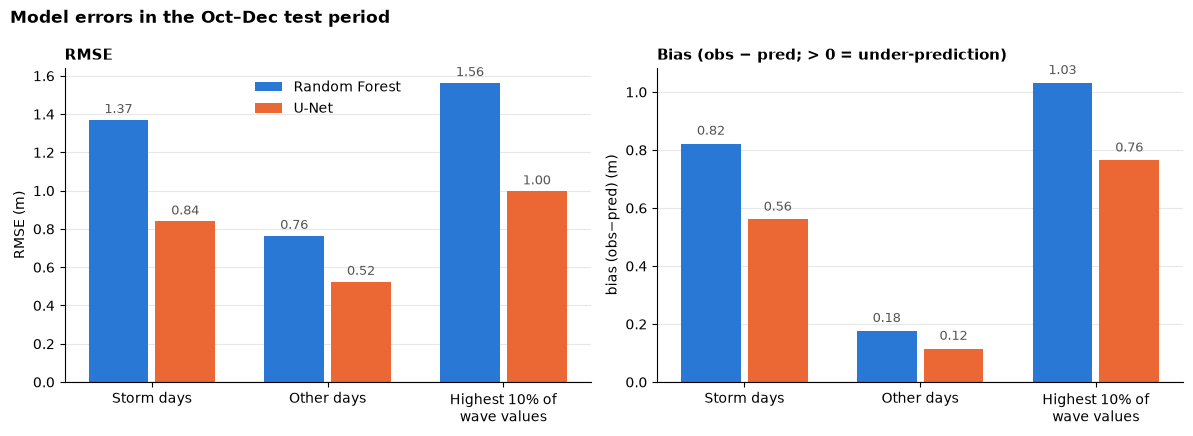

In [14]:
# -----------------------------
# ERRORS: storm days vs other days (test period)
# -----------------------------
def err_stats(o, pr):
    e = o - pr
    return {"MAE": np.mean(np.abs(e)), "RMSE": np.sqrt(np.mean(e ** 2)),
            "bias (obs−pred)": np.mean(e), "R2": r2_score(o, pr),
            "mean obs Hm0": np.mean(o), "n": e.size}

rows = []
for name, pr in preds.items():
    for lab, m in [("storm days", storm_hour), ("other days", ~storm_hour), ("all test days", np.ones_like(storm_hour))]:
        rows.append({"model": name, "days": lab, **err_stats(obs[m].ravel(), pr[m].ravel())})
    # the very highest waves: cells/hours above the P90 of all test Hm0 values
    hi = obs > np.percentile(obs, PCTL)
    rows.append({"model": name, "days": f"cells above P{PCTL} of test Hm0", **err_stats(obs[hi], pr[hi])})
errs = pd.DataFrame(rows)
errs.round(3).to_csv(EXT_DIR / "model_errors_storm_vs_other.csv", index=False)
print(errs.round(3).to_string(index=False))

labels = ["storm days", "other days", f"cells above P{PCTL} of test Hm0"]
x = np.arange(len(labels))
w = 0.38
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, metric in zip(axes, ["RMSE", "bias (obs−pred)"]):
    for off, name in [(-w / 2, "Random Forest"), (w / 2, "U-Net")]:
        vals = errs[errs.model == name].set_index("days").loc[labels, metric].to_numpy()
        bars = ax.bar(x + off, vals, width=w - 0.04, color=COLOR[name], label=name)
        for b, val in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, val + (0.02 if val >= 0 else -0.02), f"{val:.2f}",
                    ha="center", va="bottom" if val >= 0 else "top", fontsize=9, color="#555")
    ax.set_xticks(x, ["Storm days", "Other days", f"Highest 10% of\nwave values"])
    ax.axhline(0, color="#555", lw=0.8)
    ax.set_ylabel(f"{metric} (m)")
    ax.set_title(metric if metric == "RMSE" else "Bias (obs − pred; > 0 = under-prediction)", loc="left",
                 fontweight="bold", fontsize=11)
    ax.grid(axis="x", visible=False)
axes[0].legend(frameon=False)
fig.suptitle("Model errors in the Oct–Dec test period", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(EXT_DIR / "model_errors_storm_vs_other.png", dpi=300)
plt.show()

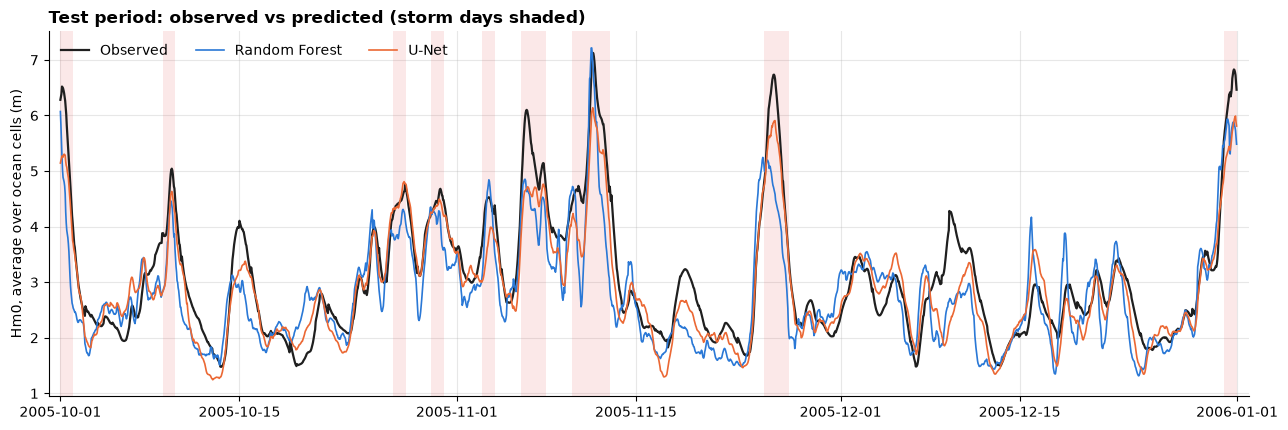

                  event  observed peak (m)  RF peak (m)  U-Net peak (m)  RF peak error (%)  U-Net peak error (%)
2005-12-31 → 2005-12-31               6.83         5.94            5.99             -13.02            -12.280000
2005-11-10 → 2005-11-12               7.13         7.21            6.14               1.24            -13.860000
2005-11-25 → 2005-11-26               6.73         5.20            5.91             -22.84            -12.290000
2005-10-01 → 2005-10-01               6.52         6.07            5.30              -6.90            -18.670000
2005-11-06 → 2005-11-07               6.10         4.85            4.76             -20.44            -21.889999
2005-10-30 → 2005-10-30               4.68         4.29            4.49              -8.29             -3.960000
2005-10-27 → 2005-10-27               4.76         4.31            4.81              -9.36              1.130000
2005-10-09 → 2005-10-09               5.04         4.46            4.63             -11.47      

In [15]:
# -----------------------------
# TEST PERIOD TIME SERIES + STORM PEAKS
# -----------------------------
hourly = pd.DataFrame({"Observed": obs.mean(1), **{k: v.mean(1) for k, v in preds.items()}},
                      index=pd.Timestamp("2005-01-01") + pd.to_timedelta(test_times, unit="h"))
fig, ax = plt.subplots(figsize=(13, 4.4))
for d in day.index[(day.storm) & (day.index.month >= 10)]:
    ax.axvspan(d, d + pd.Timedelta(days=1), color=STORM_C, alpha=0.12, lw=0)
for k in ["Observed", "Random Forest", "U-Net"]:
    ax.plot(hourly.index, hourly[k], color=COLOR[k], lw=1.6 if k == "Observed" else 1.2, label=k)
ax.set_ylabel("Hm0, average over ocean cells (m)")
ax.set_title("Test period: observed vs predicted (storm days shaded)", loc="left", fontweight="bold")
ax.legend(frameon=False, ncol=3, loc="upper left")
ax.margins(x=0.01)
fig.tight_layout()
fig.savefig(EXT_DIR / "test_period_timeseries.png", dpi=300)
plt.show()

# peak of each test-period storm event: observed vs predicted (hourly domain mean, max within the event)
peaks = []
for _, e in events[events.period == "test (Oct–Dec)"].iterrows():
    win = hourly.loc[str(e.start):str(e.end)]
    peaks.append({"event": f"{e.start} → {e.end}", "observed peak (m)": win["Observed"].max(),
                  "RF peak (m)": win["Random Forest"].max(), "U-Net peak (m)": win["U-Net"].max()})
peaks = pd.DataFrame(peaks)
if len(peaks):
    for m in ["RF", "U-Net"]:
        peaks[f"{m} peak error (%)"] = 100 * (peaks[f"{m} peak (m)"] - peaks["observed peak (m)"]) / peaks["observed peak (m)"]
peaks.round(2).to_csv(EXT_DIR / "test_storm_peaks.csv", index=False)
print(peaks.round(2).to_string(index=False))

print("\nSaved to", EXT_DIR.resolve())
for f in sorted(EXT_DIR.iterdir()):
    print(" -", f.name)